# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- 0.6.0부터 **정책을 실로봇에서 돌리는 기능이 `lerobot-record`에서 `lerobot-rollout`으로 옮겨졌다.** 평가는 반드시 `lerobot-rollout`으로 한다(2-1 참고).

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2022136044"
NAME = "민경민"
HF_USER = "mgm136044"

TASK = "Pick and place the cube"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-place-cube_20261008_100203"        # 과제 1 학습 데이터셋 -> 데이터셋은 바꿔도 됨. (0.6.0의 lerobot-record로 녹화했다면 끝에 녹화 시각이 붙어 있다)
POLICY_REPO   = f"{HF_USER}/act_pick_place_cube_remote"       # 업로드한 ACT 정책
# 평가 녹화 데이터셋 — lerobot-rollout은 이름이 rollout_로 시작해야 하고, 끝에 녹화 시각(_YYYYMMDD_HHMMSS)을 자동으로 붙인다.
# 터미널 로그나 Hub에 실제로 올라간 이름을 그대로 적을 것.
EVAL_DATASET  = f"{HF_USER}/rollout_act_pick_place_cube_20261028_093653"
WANDB_URL     = "https://wandb.ai/mkm0530-korea-university-of-technology-and-education/lerobot/runs/f7w3vtmx"                               # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2022136044 민경민
태스크        : Pick and place the cube
학습 데이터셋 : https://huggingface.co/datasets/mgm136044/pick-place-cube_20261008_100203
정책 모델     : https://huggingface.co/mgm136044/act_pick_place_cube_remote
평가 데이터셋 : https://huggingface.co/datasets/mgm136044/rollout_act_pick_place_cube_20261028_093653
wandb         : https://wandb.ai/mkm0530-korea-university-of-technology-and-education/lerobot/runs/f7w3vtmx


In [2]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [3]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] mgm136044/pick-place-cube_20261008_100203  (파일 10개)


OK   [model  ] mgm136044/act_pick_place_cube_remote  (파일 9개)


OK   [dataset] mgm136044/rollout_act_pick_place_cube_20261028_093653  (파일 9개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어
실제로 실행한 `lerobot-train` 명령어 전체 (Backend.AI 원격 GPU 서버에서 실행, W&B 런 `f7w3vtmx`에 기록된 인자와 동일).

```bash
lerobot-train \
  --dataset.repo_id=mgm136044/pick-place-cube_20261008_100203 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=mgm136044/act_pick_place_cube_remote \
  --policy.push_to_hub=true \
  --output_dir=outputs/train/act_pick_place_cube \
  --job_name=act_pick_place_cube \
  --batch_size=16 \
  --steps=100000 \
  --save_freq=5000 \
  --num_workers=8 \
  --wandb.enable=true
```

> 참고 (0.6.0)
> - `--policy.repo_id`를 주면 학습이 끝난 뒤 정책이 Hub에 자동 업로드된다. 업로드하지 않으려면 `--policy.push_to_hub=false`를 주고, 나중에 `hf upload <repo_id> outputs/train/<job>/checkpoints/last/pretrained_model`로 올린다.
> - wandb를 쓰려면 `--wandb.enable=true`를 추가하고 미리 `wandb login`을 해 둔다.
> - 이전 버전 자료의 `--eval_freq`는 `--env_eval_freq`로 이름이 바뀌었다(실로봇 학습에서는 쓰지 않는다).
> - 학습 기본값: `steps=100000`, `batch_size=8`, `save_freq=20000`.

### 1-2. 학습 환경
- GPU: Backend.AI 원격 서버의 NVIDIA Hopper 아키텍처 CUDA GPU 1개 (W&B 기록상 할당 메모리 약 37.7GB, 학습 중 사용 메모리 약 6.9GB)
- 학습 step 수: 100,000 step (batch 16, 총 1,600,000 샘플, 약 83.6 epoch)
- 소요 시간: 약 3시간 25분 (W&B runtime 12,271초, 2026-10-20)
- 기본값에서 변경한 하이퍼파라미터와 이유:
  - `batch_size` 8 → 16: GPU 메모리에 여유가 있어 한 step에 더 많은 샘플을 보고 gradient를 안정시키기 위해.
  - `save_freq` 20000 → 5000: 원격 서버 세션이 끊겨도 중간 체크포인트에서 이어갈 수 있도록 더 자주 저장.
  - `num_workers` 4 → 8: 서버 CPU 코어가 많아 데이터 로딩이 학습 속도를 막지 않도록.
  - 정책 하이퍼파라미터(chunk_size 100, n_action_steps 100, lr 1e-5, ResNet18 등)는 ACT 기본값 그대로.

In [4]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05



== 학습 설정 (train_config.json) ==
dataset   : mgm136044/pick-place-cube_20261008_100203
steps     : 100000
batch_size: 16
seed      : 1000


### 1-3. 학습 곡선
W&B 런(`train/loss`, 200 step 간격 500개 점)을 내려받아 그린 loss 곡선. 원본 값은 `images/loss.csv`에 있다.

![loss curve](images/loss_curve.png)

- loss는 6.23(200 step)에서 빠르게 떨어져 약 5,000 step에 0.3 아래, 20,000 step에 약 0.1이 되었고, 100,000 step에서 0.039로 끝났다.
- 로그 스케일로 보면 끝까지 완만하게 내려가고 있어 발산이나 큰 튐은 없었다. 다만 학습 loss만으로는 실로봇 일반화 정도를 알 수 없다(2절 결과 참고).

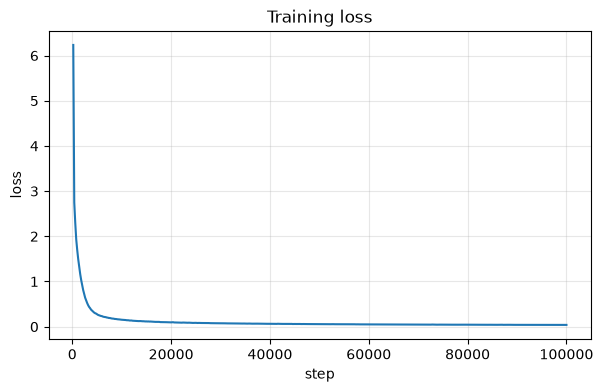

In [5]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

## 2. 실로봇 평가 (10회)

### 2-1. 평가 명령어
LeRobot 0.6.0에서는 `lerobot-record`가 데이터 수집 전용이 되었다. `--policy.path`를 받지 않으며, `eval_`로 시작하는 데이터셋 이름도 거부한다.
평가는 `lerobot-rollout`의 **episodic** 전략으로 한다. `lerobot-record`처럼 에피소드 단위로 녹화하고, 에피소드 사이에 리셋 시간을 둔다.

- `--strategy.type=base`는 녹화를 하지 않으므로 이 과제의 평가로 인정하지 않는다.
- `--dataset.repo_id`의 이름은 **`rollout_`로 시작**해야 한다. 실제 업로드되는 이름에는 녹화 시각이 자동으로 붙는다(예: `rollout_act_pick-cube_20261101_143000`). 이 이름을 0번 셀의 `EVAL_DATASET`에 적는다.
- `--robot.id`는 캘리브레이션할 때 쓴 id, 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 **같아야** 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--dataset.single_task`는 학습 데이터셋의 task 문장과 똑같이 쓴다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간 동안 리더 암으로 로봇을 되돌릴 수 있고, 생략하면 로봇이 리셋 동안 제자리에 멈춰 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료.
  (`←`로 다시 녹화한 회차는 2-2의 결과와 3절 고찰에 그 사실과 이유를 적는다.)

평가에 실제로 사용한 `lerobot-rollout` 명령어 전체:

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=mgm136044/act_pick_place_cube_remote \
  --policy.device=mps \
  --robot.type=so101_follower \
  --robot.port=/dev/tty.usbmodem5AE60550261 \
  --robot.id=follower1 \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 25}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 25}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/tty.usbmodem5AE60577591 \
  --teleop.id=leader1 \
  --fps=25 \
  --dataset.repo_id=mgm136044/rollout_act_pick_place_cube \
  --dataset.single_task="Pick and place the cube" \
  --dataset.fps=25 \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15 \
  --dataset.private=false
```

평가 환경과 예시 명령어에서 바꾼 점:
- 실습실 PC를 쓸 수 없게 되어 개인 Mac mini(Apple M4, macOS)에서 평가했다. CUDA가 없어 `--policy.device=mps`로 추론했고, 포트는 macOS 형식(`/dev/tty.usbmodem...`)이다.
- 이 Mac에는 캘리브레이션 파일이 없어 `lerobot-calibrate`로 팔로워(`follower1`)·리더(`leader1`)를 새로 캘리브레이션했고, 같은 id를 `--robot.id`/`--teleop.id`에 썼다.
- 카메라 이름은 학습 데이터셋과 같은 `overhead`, `wrist`를 썼다(예시의 `top`이 아님).
- 학습 데이터셋이 25fps이고 카메라도 640×480에서 25fps로 나와서 `--fps=25`, `--dataset.fps=25`, 카메라 fps 25로 맞췄다.
- 첫 실행은 2회차 도중 의도치 않은 ESC 입력(macOS에서는 LeRobot이 키보드 전체를 감시함)으로 2회만 녹화되고 끝났다. 이 불완전한 데이터셋은 Hub에서 삭제했고, 같은 명령으로 처음부터 10회를 새로 녹화했다. 제출한 평가 데이터셋에서는 `←`로 다시 녹화한 회차가 없다.

In [6]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

eval_name = EVAL_DATASET.split("/", 1)[-1]
print("이름 규칙 확인  :", "통과" if eval_name.startswith("rollout_") else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

평가 에피소드 수: 10
총 프레임 수    : 7233
fps             : 25
카메라          : ['observation.images.overhead', 'observation.images.wrist']

에피소드 수 확인: 통과
이름 규칙 확인  : 통과


### 2-2. 회차별 결과
성공 기준: 30초 안에 큐브를 집어 회색 매트 위에 놓고, 에피소드가 끝날 때 큐브가 매트 위에 있으면 성공.
판정은 평가 데이터셋의 overhead·wrist 영상과 현장 관찰로 했다. `←`로 다시 녹화한 회차는 없다.

In [7]:
results = [
    # episode: 평가 데이터셋의 에피소드 번호, success: True/False, note: 관찰 내용 또는 실패 원인
    {"episode": 0, "success": True,  "note": "왼쪽 앞의 큐브를 집어 매트 위에 놓고 시작 자세로 복귀(약 22초)"},
    {"episode": 1, "success": False, "note": "파지 실패: 그리퍼가 큐브 옆을 쳐서 큐브가 오른쪽 매트 밖으로 밀려남"},
    {"episode": 2, "success": False, "note": "파지 실패: 큐브 위에서 맴돌며 그리퍼를 여닫았으나 집지 못함, 큐브는 시작 위치에 남음"},
    {"episode": 3, "success": False, "note": "파지 실패: 큐브에 접근했으나 위치가 어긋나 집지 못함, 큐브가 시작 위치 근처에 남음"},
    {"episode": 4, "success": False, "note": "파지 실패: 큐브 쪽으로 내려왔으나 집지 못함, 큐브가 왼쪽 시작 위치에 남음"},
    {"episode": 5, "success": True,  "note": "약 10초에 매트 위에 놓음. 이후 빈 그리퍼로 매트 위를 다시 맴돌았지만 큐브는 매트 위에 유지"},
    {"episode": 6, "success": False, "note": "파지 실패: 오른쪽에 비스듬히 놓인 큐브에 접근했으나 집지 못함"},
    {"episode": 7, "success": False, "note": "파지 실패: 가운데 큐브에 접근했으나 집지 못하고 오른쪽으로 밀어냄"},
    {"episode": 8, "success": False, "note": "파지 실패: 손목 카메라에 큐브가 보였으나 그리퍼 위치가 어긋나 집지 못함"},
    {"episode": 9, "success": True,  "note": "약 13초에 매트 위에 놓음. 이후 빈 그리퍼로 매트 위를 맴돎(큐브는 매트 위 유지)"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df

성공률: 3/10 = 30%


,episode,success,note
0,0,True,왼쪽 앞의 큐브를 집어 매트 위에 놓고 시작 자세로 복귀(약 22초)
1,1,False,파지 실패: 그리퍼가 큐브 옆을 쳐서 큐브가 오른쪽 매트 밖으로 밀려남
2,2,False,"파지 실패: 큐브 위에서 맴돌며 그리퍼를 여닫았으나 집지 못함, 큐브는 시작 위치에 남음"
3,3,False,"파지 실패: 큐브에 접근했으나 위치가 어긋나 집지 못함, 큐브가 시작 위치 근처에 남음"
4,4,False,"파지 실패: 큐브 쪽으로 내려왔으나 집지 못함, 큐브가 왼쪽 시작 위치에 남음"
5,5,True,약 10초에 매트 위에 놓음. 이후 빈 그리퍼로 매트 위를 다시 맴돌았지만 큐브는 ...
6,6,False,파지 실패: 오른쪽에 비스듬히 놓인 큐브에 접근했으나 집지 못함
7,7,False,파지 실패: 가운데 큐브에 접근했으나 집지 못하고 오른쪽으로 밀어냄
8,8,False,파지 실패: 손목 카메라에 큐브가 보였으나 그리퍼 위치가 어긋나 집지 못함
9,9,True,약 13초에 매트 위에 놓음. 이후 빈 그리퍼로 매트 위를 맴돎(큐브는 매트 위 유지)


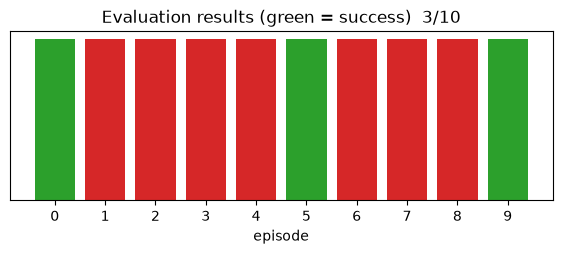

In [8]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 `mgm136044/rollout_act_pick_place_cube_20261028_093653`을 넣어 재생을 확인했다.
아래 GIF는 왼쪽이 overhead, 오른쪽이 wrist 카메라이고, 8프레임 중 1장씩 뽑아 약 3배속으로 이어 붙였다.

**성공 (episode 0)**: 큐브를 집어 매트 위에 놓고 복귀

![success](images/success.gif)

**실패 (episode 1)**: 집지 못하고 큐브를 오른쪽 매트 밖으로 밀어냄

![failure](images/failure.gif)

## 3. 고찰

**3-1. 실패 원인 분석** — 실패한 회차들에 공통된 패턴이 있었는가? 정책의 어떤 한계 때문이라고 생각하는가?

실패 7회는 모두 파지 단계에서 나왔고 한 번 집은 큐브를 옮기다 떨어뜨린 회차는 없었다. 그리퍼가 큐브 바로 옆이나 위에서 몇 cm 어긋난 채 닫히거나 큐브를 쳐서 밀어내는 모습이 반복됐다. 실패는 특정 위치에 몰리지 않았다(왼쪽 ep2·ep4, 가운데 ep3·ep7·ep8, 오른쪽 ep1·ep6). 가장 큰 원인은 환경 차이라고 본다. 평가를 실습실이 아닌 다른 책상·배경·조명에서 했고 overhead 카메라를 손으로 다시 설치해 화면 속 매트와 큐브의 크기·위치가 학습 때와 달랐다. 또 캘리브레이션을 새로 해서 같은 관절 값이 학습 때와 조금 다른 실제 자세에 대응했을 수 있다. 여기에 ACT가 100 step(25fps 기준 4초) 묶음을 한 번에 실행하는 탓에 묶음 안에서 생긴 작은 위치 오차를 바로 고치지 못한 점도 겹쳤다. 성공한 ep5·ep9에서도 큐브를 놓은 뒤 빈 그리퍼로 다시 매트 위를 맴돌았는데 정책이 "작업 완료" 상태를 따로 알지 못하고 화면에 반응해 동작을 이어 가서 생긴 일로 보인다.

**3-2. 데이터와 성능의 관계** — 과제 1에서 수집한 시연의 품질(일관성, 물체 위치 다양성 등)이 결과에 어떤 영향을 주었다고 보는가?

학습 데이터 50개 에피소드의 시작 장면을 확인해 보니 큐브 시작 위치가 로봇 앞 왼쪽·가운데·오른쪽에 넓게 퍼져 있었고 기울어진 큐브(ep45~49)도 있었다. 위치 다양성은 좋은 편이었고 덕분에 평가에서도 왼쪽(ep0)과 가운데·오른쪽(ep5·ep9) 모두에서 성공이 나왔다. 반면 50개 모두 같은 실습실 책상, 같은 매트·배경·조명, 같은 카메라 자세에서 녹화되어 시각 환경의 다양성은 전혀 없었다. 그래서 위치 변화에는 어느 정도 대응해도 배경·카메라가 바뀐 평가 환경에서는 파지 위치를 정확히 맞추지 못했다고 본다. 또 넓은 영역을 50개로 나눠 덮다 보니 위치별 시연 수가 적었고 그래서 정밀하게 맞춰야 하는 파지 단계가 가장 먼저 무너졌다고 생각한다.

**3-3. 개선 아이디어** — 성공률을 높이기 위해 데이터 수집, 학습 설정, 평가 환경 중 무엇을 어떻게 바꿔 보겠는가?

- **평가 환경**: 데이터를 모은 곳과 같은 책상·카메라 자세에서 평가한다. 카메라 거치대 위치를 표시해 두고 캘리브레이션 파일(`~/.cache/huggingface/lerobot/calibration/`)을 백업해 학습 때와 같은 기준을 쓴다.
- **데이터 수집**: 새 환경에서 20~30개 시연을 추가로 녹화해 기존 정책을 이어서 학습한다(fine-tuning). 녹화할 때 조명·배경을 바꿔 가며 시각 다양성을 늘린다. 파지가 어려웠던 위치는 시연을 더 모은다.
- **학습 설정**: `--dataset.image_transforms.enable=true`로 밝기·대비 등 이미지 증강을 켜서 환경 변화에 덜 민감하게 만든다.
- **추론 설정**: `--policy.temporal_ensemble_coeff=0.01 --policy.n_action_steps=1`(temporal ensembling)이나 더 작은 `n_action_steps`로 자주 다시 예측하게 해서 파지 직전의 위치 오차를 바로 고친다. 매 step 추론이 필요하니 MPS에서 25fps가 유지되는지 먼저 확인한다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [9]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": EVAL_DATASET.split("/", 1)[-1].startswith("rollout_"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
